# PRC plots
Plots from `PRC_sweep.csv` using the functions in `PRC_plots.py`. Set the parameters in the cell below, then run all.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PRC_plots import *

In [2]:
# ----------------------------- PARAMETERS -----------------------------
DATA = "PRC_sweep.csv"

# single PRC plot
PRC_F = 0                   # autapse strength f to show
PRC_HUE = "I_h"             # one line per value of this column

# comparison (a vs b, and b - a)
COMPARE_F = (100, 200)        # (f_a, f_b)
COMPARE_LABELS = ("no autapse", "autapse")

# waterfall
WATERFALL_I0 = 150          # I_0 (pA) to show all f values for
WATERFALL_OFFSET = None     # vertical shift between curves; None = automatic

# area / mean perturbation time vs I_0
METRIC_F = None             # list of f values to include; None = all

SAVE = False                # save figures as png
# ----------------------------------------------------------------------

In [3]:
df = pd.read_csv(DATA)
print("f:", np.sort(df["f"].unique()))
print("I_0:", np.sort(df["I_h"].unique()))
df_metric = df if METRIC_F is None else df[df["f"].isin(METRIC_F)]

f: [  0  10  20  30  40  50  60  70  80  90 100 110 120 130 140 150 160 170
 180 190 200 210 220 230 240 250 260 270 280 290 300 310 320 330 340 350
 360 370 380 390]
I_0: [100. 150. 200. 250.]


## PRC

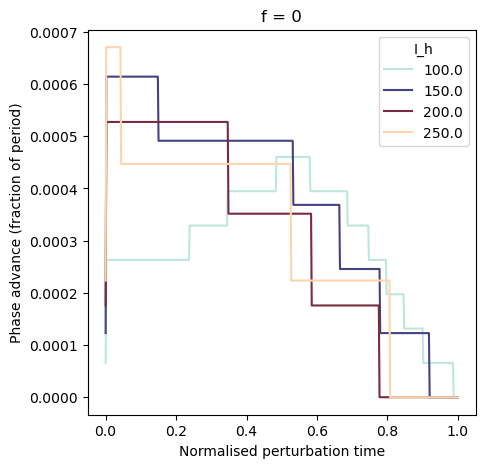

In [4]:
ax = plot_prc(select(df, f=PRC_F), hue=PRC_HUE)
ax.set_title(f"f = {PRC_F}")
if SAVE: plt.savefig(f"PRC_f{PRC_F}.png")
plt.show()

## Comparison of two autapse strengths

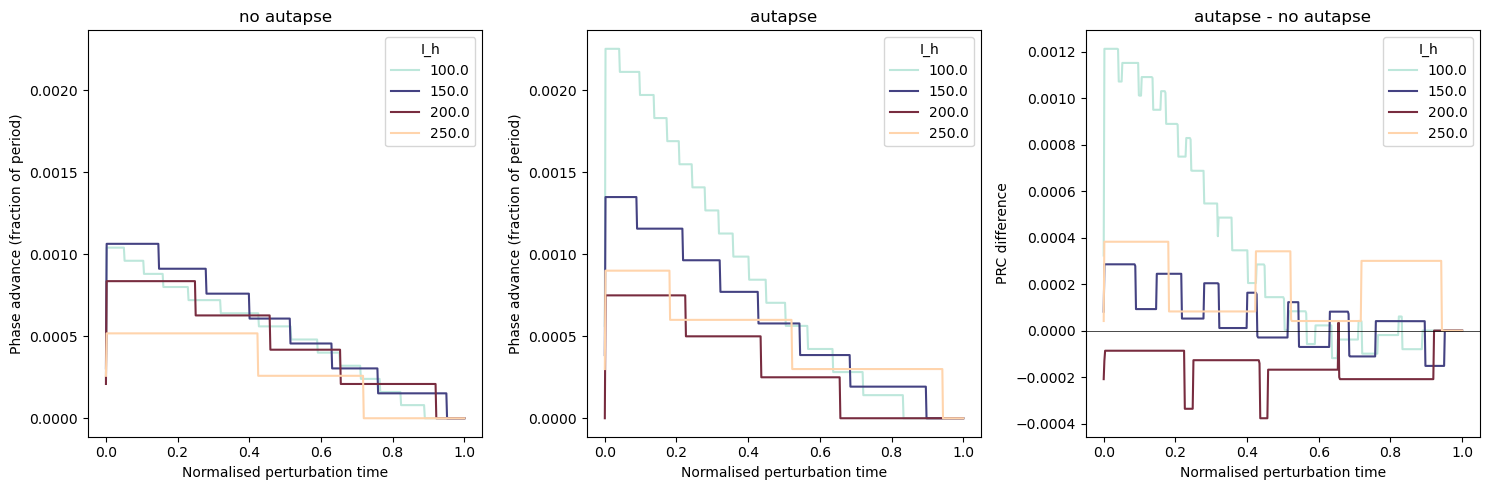

In [5]:
f_a, f_b = COMPARE_F
ax = plot_prc_compare(select(df, f=f_a), select(df, f=f_b), labels=COMPARE_LABELS)
if SAVE: plt.savefig(f"PRC_compare_f{f_a}_f{f_b}.png")
plt.show()

## Waterfall over f

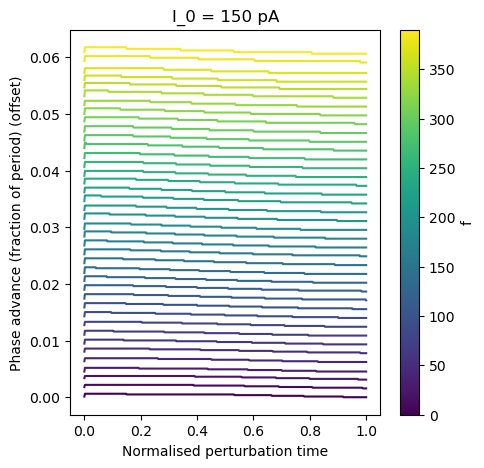

In [6]:
ax = plot_prc_waterfall(df, WATERFALL_I0, offset=WATERFALL_OFFSET)
if SAVE: plt.savefig(f"PRC_waterfall_I{WATERFALL_I0}.png")
plt.show()

## Area under the PRC vs I_0

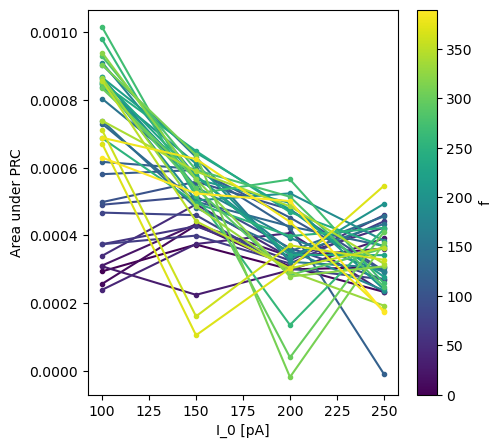

In [7]:
ax = plot_area_vs_I(df_metric)
if SAVE: plt.savefig("PRC_area_vs_I.png")
plt.show()

## Mean perturbation time vs I_0
PRC-weighted; unreliable where a PRC sums to ~0.

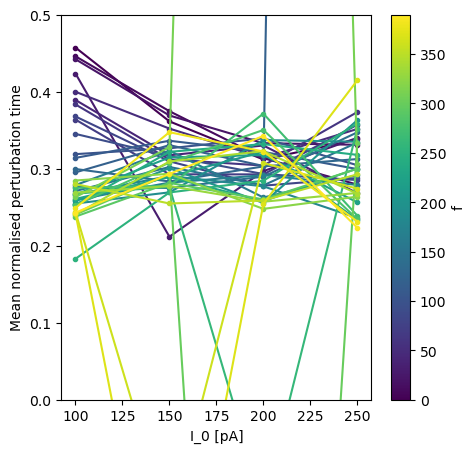

In [8]:
ax = plot_mean_time_vs_I(df_metric)
ax.set_ylim((0, 0.5))
if SAVE: plt.savefig("PRC_mean_time_vs_I.png")
plt.show()

## Area under the PRC vs firing rate

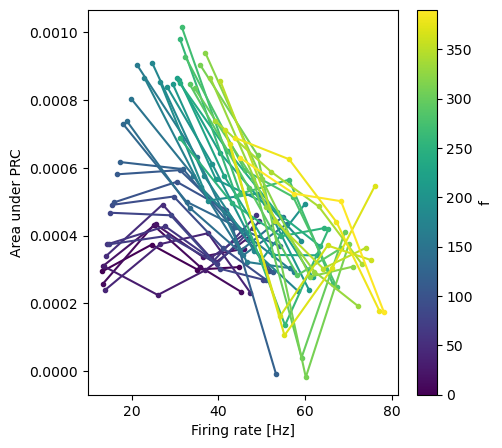

In [9]:
ax = plot_area_vs_Hz(df_metric)
if SAVE: plt.savefig("PRC_area_vs_Hz.png")
plt.show()

## Mean perturbation time vs firing rate
PRC-weighted; unreliable where a PRC sums to ~0.

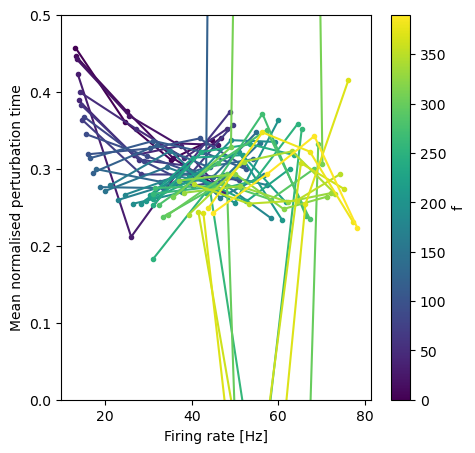

In [11]:
ax = plot_mean_time_vs_Hz(df_metric)
ax.set_ylim((0, 0.5))
if SAVE: plt.savefig("PRC_mean_time_vs_Hz.png")
plt.show()